# How to use autoMCCD-lite: one record in, one certificate out

This notebook walks you through a single run of the pipeline from the outside, the way a registry
system would use it. You send one clinical record to the running api, and you get back a WHO
Medical Certificate of Cause of Death coded in ICD-11, with a route that says whether a human
needs to look at it and the reasons why.

You will see four pictures of the same result, each answering one question:

1. **The certificate as the WHO form**: what would be printed.
2. **The record with the evidence highlighted**: where every certified line came from.
3. **The flow diagram**: what each stage did to this record, with the live numbers.
4. **The charts over the evaluation run**: how the pipeline does over the 17 teaching cases.

Everything here runs live against your stack, so the outputs you see are yours. Start the stack
with `make up` and wait for `/readyz` to say ready; the WHO container takes about a minute to load
its release the first time.


In [1]:
import json, time, copy
import httpx
from _helpers import *  # display helpers; the pipeline itself lives in automccd_lite
from automccd_lite.config import settings

cfg = settings()
API = f"http://localhost:{__import__('os').environ.get('API_PORT', '8000')}"
ready = httpx.get(f"{API}/readyz", timeout=30).json()
print(json.dumps(ready, indent=2))
assert ready["ready"], "run `make up` first and wait for the icd-api to load its release"

{
  "ready": true,
  "components": {
    "postgres": true,
    "icd_api": true,
    "storage": true,
    "model_configured": true
  }
}


## 1. The input: a death record

A record is a small JSON document: who died (`record_id`, `sex`, `age` with its `age_unit`) and one
or more free-text `notes`, each with a `name`. The names matter later: when the model cites
evidence, it names the note it quoted from, and the validator checks the quote against that note.

S01 is the first of the 24 teaching scenarios the client gave us. Read the narrative once before
you run anything, and decide for yourself what the chain of causes was. You will compare your
answer with the model's in a moment.


In [2]:
record = load_record("S01")
show_json(record)

{
  "record_id": "S01",
  "sex": "male",
  "age": 49.0,
  "age_unit": "years",
  "context": null,
  "notes": [
    {
      "name": "case_narrative",
      "text": "A male aged 49 years was admitted to hospital with a history of fever, disorientation and drow…
    }
  ]
}


## 2. Send it to the api

`POST /certify` takes the record and runs every stage before it answers, which is why a call takes
a few seconds. Most of that time is the language model writing the draft; the WHO coding calls take
milliseconds. You get one JSON body back.


In [3]:
t0 = time.perf_counter()
r = httpx.post(f"{API}/certify", json=record.model_dump(mode="json"), timeout=300)
r.raise_for_status()
resp = r.json()
print(f"HTTP {r.status_code} in {time.perf_counter() - t0:.1f} s")
print("route  :", resp["route"])
print("reasons:", resp["reasons"])

HTTP 200 in 8.7 s
route  : review
reasons: ['validator:V6', 'revised', 'low_confidence', 'codedit:BER-CE-1', 'codedit:BER-CE-22']


## 3. Read the response

The body has seven parts. Look at them in this order:

- `route` and `reasons`: the decision. `auto` means nothing stopped the certificate from being
  accepted as written; `review` means a human should look, and `reasons` lists every reason code
  that applies. A reviewer who sees `low_confidence` and `codedit:FER-CE-931` knows exactly what to
  check.
- `certificate`: the MCCD the model wrote, in the strict JSON shape the prompt's schema defines.
- `coding`: what the WHO tools said: the ICD-11 code per line, the match score of each, and the
  underlying cause of death DORIS selected (`ucod_stem`).
- `versions`: the prompt hash, the model and the ICD release that produced this. Two certificates
  with the same versions are comparable; two with different ones are not.
- `usage` and `timings_ms`: what it cost.

The validation details and the raw WHO responses are not in the body. They are stored with the
certificate in Postgres, and you will read them from there in section 6.


In [4]:
show_json(resp, keys=["record_id", "route", "reasons", "coding", "versions", "usage", "timings_ms"])

{
  "record_id": "S01",
  "route": "review",
  "reasons": [
    "validator:V6",
    "revised",
    "low_confidence",
    "codedit:BER-CE-1",
    "codedit:BER-CE-22"
  ],
  "coding": {
    "ucod_stem": "1G41",
    "ucod_full": "1G41",
    "codes": {
      "part1": [
        "1G41",
        "1B54",
        "MA15.0"
      ],
      "part2": [
        "5A11",
        "NE84"
      ]
    },
    "code_scores": [
      1.0,
      1.0,
      1.0
    ],
    "codedit_issues": [
      "BER-CE-1",
      "BER-CE-22"
    ],
    "doris_warning": "The following conditions - NE84 - were reported without an external cause, a default ex…
  },
  "versions": {
    "prompt_version": "4.7",
    "prompt_sha1": "d051044cd4a12f9a46085b23869a4ed70623719e",
    "schema_version": "v1.1",
    "model": "gpt-5-nano-2025-08-07",
    "icd_release": "2026-01",
    "automccd_version": "0.1.0"
  },
  "usage": {
    "prompt_tokens": 11001,
    "completion_tokens": 751,
    "reasoning_tokens": 0,
    "calls": 2
  },
  "timing

## 4. The certificate as the WHO form

Part I is read from the bottom up: the condition on the lowest used line started the sequence,
and each line above it is a consequence of the line below. Line 1a is what the person died of
directly. The interval column says how long before death each condition began, so intervals must
not shrink as you go down the chain. Part II holds conditions that contributed but were not part
of that sequence.

The small blue code at the right of each line is the ICD-11 code autocode assigned to the term.
If a line has no code, autocode could not match the wording, and the route tells you so with
`part1_line_uncoded`.


In [5]:
coding = resp.get("coding") or {}
render_mccd(resp["certificate"], coding.get("codes"), title=f"{resp['record_id']}: route {resp['route']}")

## 5. The record with the evidence highlighted

Every line the model certifies must quote the record verbatim: the `evidence_span` must appear,
character for character up to layout, in the note the `evidence_field` names. The highlighter
below uses the same tolerant comparison as validator rule V1, so what you see highlighted is what
V1 accepted. A span V1 rejects shows up at the bottom in red: that is a fabricated or edited quote,
and the pipeline sends such a draft back for one revision before it goes to a reviewer.

Read the superscript labels: `1a`, `1b` are Part I lines, `II.1` is the first Part II entry.


In [6]:
highlight_spans(record, resp["certificate"])

## 6. What was stored: the row and the blob

The api keeps two copies of every result. The JSON body you just received goes to Blob storage
under `certificates/{date}/{time}Z_{record_id}.json`, and one row goes to the `certificates` table
with everything the body left out: the validator's findings, both revisions, and the raw DORIS and
CoDEdit replies. The row is the provenance a reviewer or an audit reads; the blob is the artefact
a downstream system picks up.

Both are written in one transaction with the pipeline run, so a failure leaves nothing half-stored.


In [7]:
from sqlalchemy import select
from automccd_lite.db import CertificateRow, session_scope
from automccd_lite.storage import BlobStorage

with session_scope() as s:
    row = s.scalars(select(CertificateRow).where(CertificateRow.record_id == "S01")
                    .order_by(CertificateRow.id.desc())).first()
print("row id       :", row.id, "created", row.created_at.isoformat(timespec="seconds"))
print("route/reasons:", row.route, row.reasons)
print("blob_path    :", row.blob_path, "exists:", BlobStorage(cfg).exists(row.blob_path))
print("validation   :", {k: row.validation[k] for k in ("schema_ok", "validator_passed", "rules_fired", "revised", "revise_rejected", "term_revision", "confidence")})
print("coding keys  :", list((row.coding or {}).keys()))

row id       : 7 created 2026-10-27T04:34:11+00:00
route/reasons: review ['validator:V6', 'revised', 'low_confidence', 'codedit:BER-CE-1', 'codedit:BER-CE-22']
blob_path    : certificates/2026-10-27/043411Z_S01.json exists: True
validation   : {'schema_ok': True, 'validator_passed': False, 'rules_fired': ['V6'], 'revised': True, 'revise_rejected': None, 'term_revision': None, 'confidence': 'moderate'}
coding keys  : ['codes', 'doris', 'codedit', 'autocode', 'code_scores', 'codedit_ucod', 'uncoded_part1']


## 7. The flow diagram, with this record's live values

The stored row holds enough to rebuild the full `Certificate` object, provenance included. From it
you can draw what happened at each stage: the model status and the time it took, which rules fired
at the gate, whether a revision ran and was adopted, the codes and the underlying cause, and the
final route with its reasons. Orange boxes are where this record hit a problem; blue ones passed.


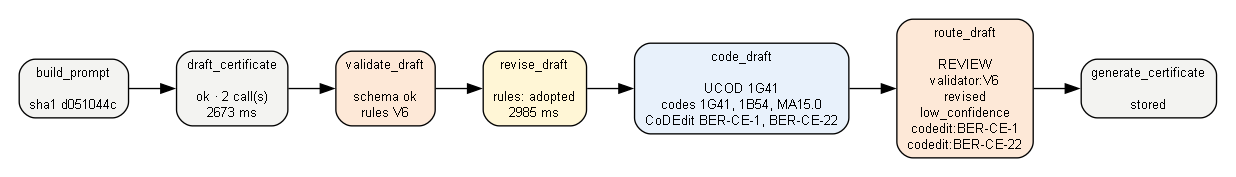

In [8]:
from automccd_lite.models import Certificate, CodedDraft, CodingSummary, DraftValidation, Usage, Versions
from automccd_lite.certificate import coding_summary

coded = CodedDraft(**row.coding) if row.coding else None
cert = Certificate(
    record_id=row.record_id, route=row.route, reasons=row.reasons, certificate=row.certificate,
    coding=coding_summary(coded), versions=Versions(**row.versions), usage=Usage(**row.usage),
    timings_ms=row.timings_ms, draft_status=row.draft_status,
    validation=DraftValidation(**row.validation) if row.validation else None, coded=coded, icd_error=row.icd_error,
)
flow_diagram(cert)

## 8. The evaluation: how the pipeline does on the 17 teaching cases

One record tells you little. The mini harness runs the pipeline on the 17 headline scenarios the
client gave us with answers, scores each one, and writes a `runs/headline_<time>Z/` folder with
`results.json` and a readable `summary.md`. It runs in-process (no api, no database), so you can
run it from this notebook. It makes about 24 model calls and takes a minute or two.

Four numbers matter, and you will see each one below:

- **Validator clean, first pass**: how often the model's first draft passed all ten rules. This is
  the model's discipline.
- **Validator clean, final**: the same after the one revision the pipeline allows. The gap between
  the two is what the repair loop buys you.
- **Auto share**: how many certificates needed no human. Expect this to be low; the gate is
  deliberately strict, and `low_confidence` alone sends a certificate to review.
- **UCOD exact vs gold**: whether DORIS picked the same underlying cause from the model's chain as
  from the client's answer. Both chains are coded through the same tools, so this compares code
  against code and never word against word.

One warning before you read them: this model does not return the same draft twice, so each number
moves by several points from run to run on 17 cases. Treat one run as a sketch. When you change the
prompt or the model, run the harness a few times and compare the ranges, not two single runs.


In [9]:
from automccd_lite.config import ROOT
from automccd_lite.eval import run

res = run("headline", quiet=True)
s = res["summary"]
print("run folder            :", res["run_dir"].relative_to(ROOT))
print("validator clean, first:", s["validator_clean_first_pass"], "%")
print("validator clean, final:", s["validator_clean"], "%   (revised once:", s["revised"], ")")
print("auto share            :", s["auto_share"], "%")
print("UCOD exact vs gold    :", s["gold_ucod_exact"], "% of", s["gold_compared"])
print("reasons seen          :", s["reasons"])

run folder            : runs\headline_043435Z
validator clean, first: 52.9 %
validator clean, final: 88.2 %   (revised once: 8 )
auto share            : 0.0 %
UCOD exact vs gold    : 41.2 % of 17
reasons seen          : {'low_confidence': 17, 'codedit:BER-CE-1': 2, 'validator:V1': 2, 'revised': 8, 'autocode_low_score': 1, 'codedit:BER-CE-10': 1, 'codedit:FER-CE-873': 1, 'codedit:FER-CE-993': 2, 'codedit:BER-CE-22': 1, 'codedit:FER-CE-934': 1}


### Reading the charts

Left: the routes. Middle: which rules fired on the first draft (orange) and how many were still
firing after the revision (blue); a rule that drops to zero is one the revision fixes reliably.
Right: how the model's underlying cause compared with the gold's, by DORIS stem code.

Below them, time per case by stage. Nearly all of it is the model; a case with an orange segment
needed a revision call. Then the per-case table, which is the same information the `summary.md`
file carries.


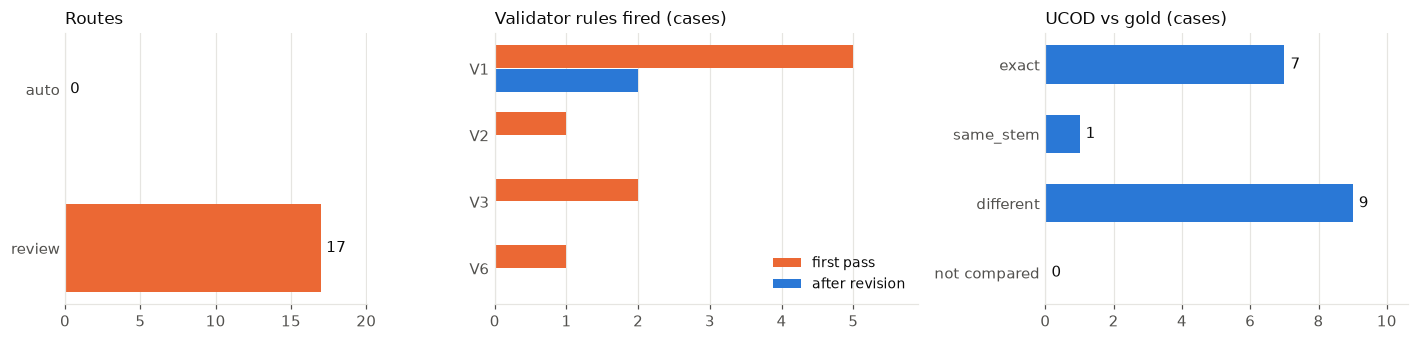

In [10]:
charts(res["rows"]);

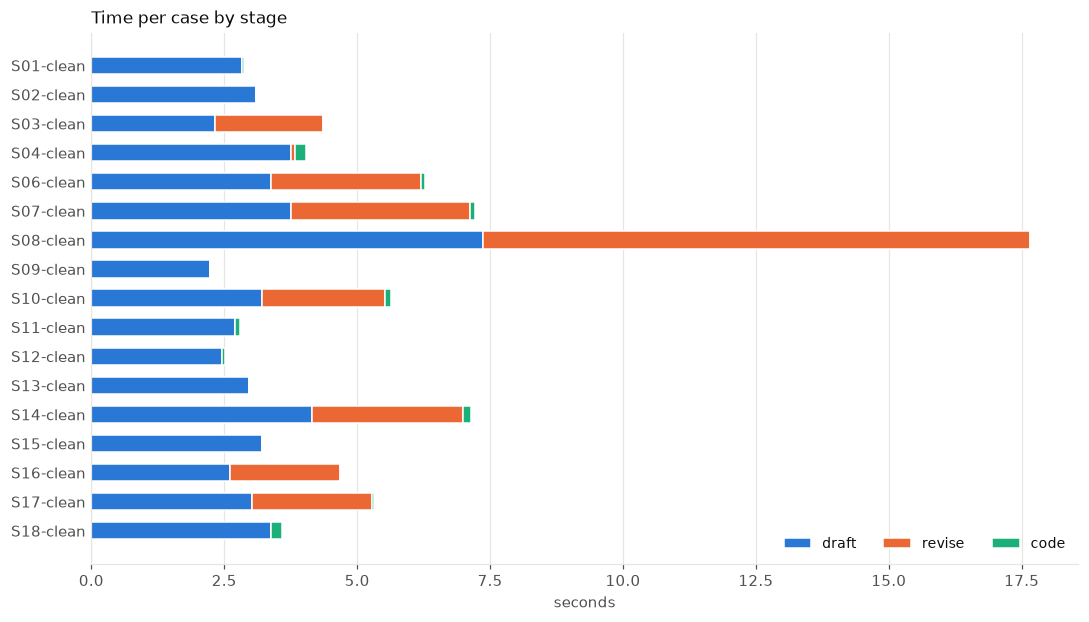

In [11]:
timings_chart(res["rows"]);

In [12]:
reason_table(res["rows"])

case,route,reasons,rules first → final,UCOD model / gold,match
S01-clean,review,"low_confidence, codedit:BER-CE-1",– → –,1G41 / 1B54,different
S02-clean,review,low_confidence,– → –,8B11.5Z / 8B11.5Z,exact
S03-clean,review,"validator:V1, revised, low_confidence","V1,V3 → V1",DC3Y / DC32.3,different
S04-clean,review,low_confidence,– → –,BA41.Z / BA41.Z,exact
S06-clean,review,"revised, low_confidence",V2 → –,CA22.0 / CA22.Z,same_stem
S07-clean,review,"revised, low_confidence",V6 → –,5A11 / 5A11,exact
S08-clean,review,"revised, low_confidence, autocode_low_score, codedit:BER-CE-1",V1 → –,PB6Z / LA89.Z,different
S09-clean,review,low_confidence,– → –,DC50.Z / DA63.Y,different
S10-clean,review,"revised, low_confidence",V1 → –,LA88.2Z / LA88.2Z,exact
S11-clean,review,"low_confidence, codedit:BER-CE-10, codedit:FER-CE-873, codedit:FER-CE-993",– → –,JB64.4 / 2B90.3Z,different


## 9. What to try next

- **Change the prompt** in `prompts/mccd/v4.7.md` (copy it to `v4.8.md` and set `prompt.version` in
  `config/default.yaml`). The `prompt_sha1` in every certificate changes with it, so runs stay
  comparable only within a version. Rerun the harness and compare the four numbers.
- **Change the model** with `LLM_MODEL` in `.env`. A stronger model raises the first-pass number
  before anything else.
- **Run the stress sample** with `make eval EVAL_SET=robust`: 34 corrupted and unusual records
  (OCR noise, truncation, a second patient's page, handwritten notes), scored on behaviour only.
  Did the pipeline decline what it should decline, and never certify what it must not?
- **Open `mccd_guide.ipynb`** for the long version: what a death certificate is, how ICD-11 and
  DORIS work, and each stage of this pipeline run on S01 with its options.
